# Which GPU tiers each method dispatches, over time

For every time window (default 60 s of simulated time) we count how many dispatches went to
Xavier, Orin and Thor vehicles, then plot one line per tier, one panel per method.

* Line = mean over the seeds, shaded band = lowest to highest seed.
* Each run stops at its own **TTA@85 %** (`STOP_AT`), so every method ends at a different simulated time.
  A run that never reaches 85 % keeps its whole run.
* A method's line ends at its **earliest** seed's stop, so every window averages all seeds.
  Dotted vertical lines mark each seed's own TTA@85 %.
* Smoothing (rolling mean over a few windows) is for the picture only; the table at the end uses raw counts.

With `STOP_AT = None` every method is cut at one common horizon instead (the earliest last dispatch of
all runs), which gives the same numbers as `wen_env/tools/tier_dispatch_views.py --views lines`.
Kernel: **Python (plato .venv)**. Everything you are likely to change is in the next cell.

In [30]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ---- settings ---------------------------------------------------------------
SCENARIO = "S1"                   # "S1" or "S2"
SEEDS = [4126, 4127, 4128]

# panel title -> run name without "S1_" / "_s<seed>"; panels appear in this order
METHODS = {
    "Ours": "gpu",
    "RA-MaOVSM (Wen et al.)": "wen_fresh",
    "Wen et al. + GPU": "wen_fresh_gpu",
    "Polaris": "polaris",
    "Random": "random",
}

BIN_S = 60                        # window width (simulated seconds)
SMOOTH = 3                        # rolling mean over this many windows (1 = no smoothing)
STOP_AT = 0.85                    # each run stops at its first evaluation >= this accuracy
                                  # None = one common horizon for all runs (earliest last dispatch)
SHOW_BAND = False                  # shade lowest..highest seed

TIERS = ["xavier", "orin", "thor"]
TIER_LABEL = {"xavier": "Xavier", "orin": "Orin", "thor": "Thor"}
TIER_COLOR = {"xavier": "#e8382c", "orin": "#d97a3f", "thor": "#2f6b34"}

FIGSIZE = (18.5, 3.4)             # about 3.7 in per panel
SAVE = False                      # True = write PNG (300 dpi) + PDF to FIG_DIR
# -----------------------------------------------------------------------------

# folder that holds runs/wen_env, wherever the notebook is opened from
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "runs" / "wen_env").is_dir())
RUNS_DIR = BASE / "runs" / "wen_env"
FIG_DIR = BASE / "wen_env" / "evidence" / f"figs_{SCENARIO.lower()}"

## 1. Load the dispatch logs

One row per dispatch: when it was sent (`t_dispatch`, simulated seconds) and the vehicle's GPU `tier`.
Seed 4126 is read from `_phaseA/` when it is there, the same lookup as the report scripts
(for S1 Ours this is the run that hung at r1957 when the disk filled).

In [31]:
def run_dir(name, seed):
    phase_a = RUNS_DIR / "_phaseA" / f"{name}_s{seed}"
    if seed == 4126 and phase_a.exists():
        return phase_a
    return RUNS_DIR / f"{name}_s{seed}"


parts, stops = [], []
for method, run in METHODS.items():
    for seed in SEEDS:
        folder = run_dir(f"{SCENARIO}_{run}", seed)
        df = pd.read_csv(folder / "dispatch_log.csv", usecols=["t_dispatch", "tier"])
        df["method"] = method
        df["seed"] = seed
        parts.append(df)

        # when does this run stop? first evaluation at or above STOP_AT, else its last dispatch
        acc = pd.read_csv(next((folder / "results").glob("*.csv")))
        hit = acc[acc["accuracy"] >= STOP_AT] if STOP_AT else acc.iloc[:0]
        reached = len(hit) > 0
        stop_s = hit["elapsed_time"].iloc[0] if reached else df["t_dispatch"].max()
        stops.append({"method": method, "seed": seed, "stop_s": stop_s, "reached": reached})

dispatches = pd.concat(parts, ignore_index=True)
stops = pd.DataFrame(stops).set_index(["method", "seed"])
stops["stop_s"].unstack().round(0)

seed,4126,4127,4128
method,,,
Ours,2089.0,2616.0,2581.0
Polaris,2452.0,2924.0,2976.0
RA-MaOVSM (Wen et al.),7263.0,6844.0,9109.0
Random,2568.0,3177.0,3559.0
Wen et al. + GPU,5046.0,4529.0,12211.0


## 2. Where each method ends

`STOP_AT` set: a method ends at its earliest seed's stop. `STOP_AT = None`: every method ends at the
earliest last dispatch of all runs. Either way the end is rounded down to a whole window, so the last
window is not a partial one.

In [32]:
if STOP_AT:
    first_stop = stops["stop_s"].groupby("method").min()
else:
    first_stop = pd.Series(stops["stop_s"].min(), index=list(METHODS))

end_s = (first_stop // BIN_S * BIN_S).reindex(list(METHODS))   # method -> end of its last window
n_bins = (end_s // BIN_S).astype(int)                           # method -> number of windows

for method in METHODS:
    s = stops.loc[method]
    seeds = ", ".join(f"{seed}: {row.stop_s:,.0f} s" + ("" if row.reached else " (not reached, whole run)")
                      for seed, row in s.iterrows())
    print(f"{method:24s} ends at {end_s[method]:6,.0f} s  ({n_bins[method]} windows)   stops: {seeds}")

Ours                     ends at  2,040 s  (34 windows)   stops: 4126: 2,089 s, 4127: 2,616 s, 4128: 2,581 s
RA-MaOVSM (Wen et al.)   ends at  6,840 s  (114 windows)   stops: 4126: 7,263 s, 4127: 6,844 s, 4128: 9,109 s
Wen et al. + GPU         ends at  4,500 s  (75 windows)   stops: 4126: 5,046 s, 4127: 4,529 s, 4128: 12,211 s (not reached, whole run)
Polaris                  ends at  2,400 s  (40 windows)   stops: 4126: 2,452 s, 4127: 2,924 s, 4128: 2,976 s
Random                   ends at  2,520 s  (42 windows)   stops: 4126: 2,568 s, 4127: 3,177 s, 4128: 3,559 s


## 3. Count dispatches per window and tier

`counts` has one row per (method, seed, window, tier), up to that method's end. Windows with no dispatch
of a tier are kept as 0.

In [33]:
d = dispatches[dispatches["t_dispatch"] < dispatches["method"].map(end_s)].copy()
d["bin"] = (d["t_dispatch"] // BIN_S).astype(int)

all_rows = pd.MultiIndex.from_tuples(
    [(m, s, b, t) for m in METHODS for s in SEEDS for b in range(n_bins[m]) for t in TIERS],
    names=["method", "seed", "bin", "tier"])
counts = (d.groupby(["method", "seed", "bin", "tier"]).size()
           .reindex(all_rows, fill_value=0)
           .rename("count")
           .reset_index())
counts["t_start"] = counts["bin"] * BIN_S
counts.head()

,method,seed,bin,tier,count,t_start
0,Ours,4126,0,xavier,0,0
1,Ours,4126,0,orin,15,0
2,Ours,4126,0,thor,6,0
3,Ours,4126,1,xavier,2,60
4,Ours,4126,1,orin,8,60


## 4. Plot

For each method and tier: smooth each seed's series, then draw the mean line and the lowest..highest band.
All panels share one time axis, so a shorter line means the method reached 85 % sooner.

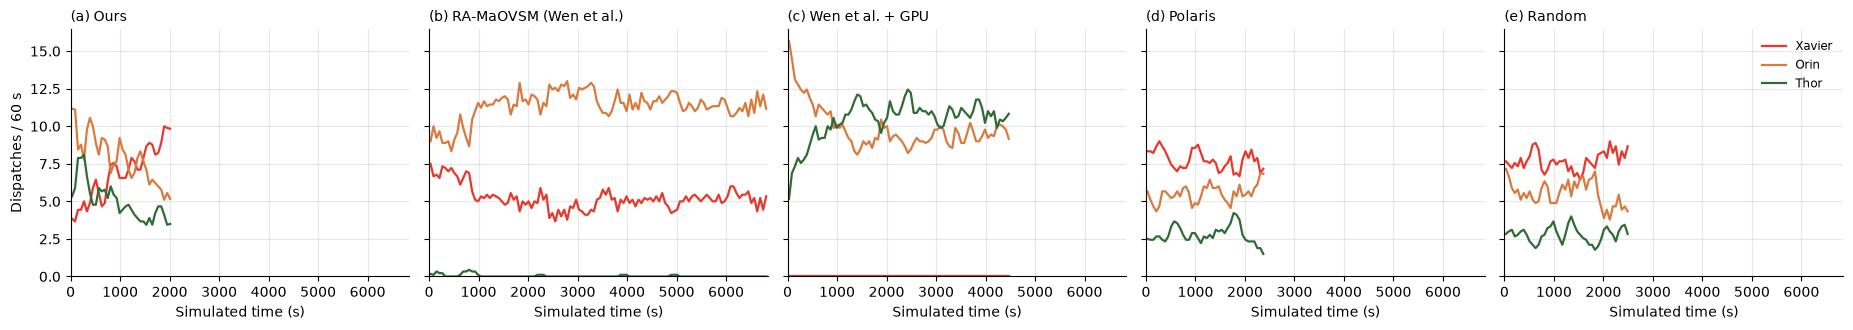

In [36]:
def seed_matrix(method, tier):
    """Rows = seeds, columns = windows, smoothed for display."""
    c = counts[(counts["method"] == method) & (counts["tier"] == tier)]
    m = c.pivot(index="seed", columns="bin", values="count")
    return m.T.rolling(SMOOTH, center=True, min_periods=1).mean().T.to_numpy()


def plot_tier_lines():
    fig, axes = plt.subplots(1, len(METHODS), figsize=FIGSIZE, sharex=True, sharey=True)

    for i, (ax, method) in enumerate(zip(axes, METHODS)):
        x = (np.arange(n_bins[method]) + 0.5) * BIN_S     # middle of each window
        for tier in TIERS:
            ys = seed_matrix(method, tier)
            color = TIER_COLOR[tier]
            if SHOW_BAND:
                ax.fill_between(x, ys.min(axis=0), ys.max(axis=0), color=color, alpha=0.18, lw=0)
            ax.plot(x, ys.mean(axis=0), color=color, lw=1.6, label=TIER_LABEL[tier])

        # if STOP_AT:   # each seed's own TTA, dotted
        #     for row in stops.loc[method].itertuples():
        #         if row.reached:
        #             ax.axvline(row.stop_s, color="#8a8984", lw=0.8, ls=":")
        ax.set_title(f"({'abcdefgh'[i]}) {method}", loc="left", fontsize=10)
        ax.set_xlabel("Simulated time (s)")
        ax.grid(alpha=0.3)
        ax.spines[["top", "right"]].set_visible(False)

    axes[0].set_xlim(0, end_s.max())   # x-axis ends where the longest method ends
    axes[0].set_ylim(bottom=0)     # likewise, so no panel is clipped
    axes[0].set_ylabel(f"Dispatches / {BIN_S} s")
    axes[-1].legend(loc="upper right", frameon=False, fontsize=8.5)
    fig.tight_layout()

    if SAVE:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        name = f"{SCENARIO.lower()}_tier_view_lines" + (f"_to{STOP_AT * 100:.0f}" if STOP_AT else "")
        for ext in ("png", "pdf"):
            fig.savefig(FIG_DIR / f"{name}.{ext}", dpi=300, bbox_inches="tight")
        print("saved", FIG_DIR / name)
    plt.show()


plot_tier_lines()

## 5. Numbers behind the figure

Mean dispatches per window (raw counts, mean over seeds) in the first and last quarter of each method's
own time span, and each tier's share over that span.

In [ ]:
per_bin = counts.groupby(["method", "tier", "bin"])["count"].mean()   # mean over seeds
rows = {}
for method in METHODS:
    q = n_bins[method] // 4
    row = {"end (s)": end_s[method]}
    for tier in TIERS:
        s = per_bin.loc[(method, tier)]
        row[f"{TIER_LABEL[tier]} first ¼"] = s.iloc[:q].mean()
        row[f"{TIER_LABEL[tier]} last ¼"] = s.iloc[-q:].mean()
    total = counts[counts["method"] == method].groupby("tier")["count"].sum().reindex(TIERS)
    for tier in TIERS:
        row[f"{TIER_LABEL[tier]} share (%)"] = total[tier] / total.sum() * 100
    row[f"total / {BIN_S} s"] = total.sum() / len(SEEDS) / n_bins[method]
    rows[method] = row

pd.DataFrame(rows).T.round(2)

,end (s),Xavier first ¼,Xavier last ¼,Orin first ¼,Orin last ¼,Thor first ¼,Thor last ¼,Xavier share (%),Orin share (%),Thor share (%),total / 60 s
Ours,2040.0,4.46,9.08,10.04,5.88,6.38,3.92,34.69,40.12,25.19,19.70
RA-MaOVSM (Wen et al.),6840.0,6.04,5.20,10.40,11.33,0.11,0.00,31.45,68.34,0.21,16.63
Wen et al. + GPU,4500.0,0.00,0.00,11.85,9.52,8.70,10.83,0.00,48.71,51.29,20.28
Polaris,2400.0,8.17,7.50,5.30,5.93,2.73,2.57,48.34,34.32,17.34,16.05
Random,2520.0,7.60,8.23,5.83,4.50,2.83,2.97,48.02,34.57,17.41,16.00
